# 07 · The hadron pair: the wake in hadrons

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jhputschke/js-contrib/blob/main/tutorials/pyjetscape/07_hadron_pair.ipynb)

**Time:** 45 minutes · **Needs:** any setup · **Data:** `auau_pair_mini`: the hadron and particlize files (0.8 GB, downloaded once)

Tutorial 06 found the jet's wake in the fluid. Experiments see hadrons, so the question is
whether the wake survives the step from fluid to hadrons, and what it looks like there.

The production samples hadrons from both freeze-out surfaces: `bulk_jet` from the jet leg
and `bulk_bg` from the background. Their difference is the wake in hadrons, and adding
`jet_frag` (the jet's own hadrons) gives the whole jet event. This tutorial:
- measures that difference with `HadronFileReader` and correlated sampling;
- shows the wake's shape around the jet;
- checks its energy against the fluid's;
- compares its spectrum and chemistry with the bulk's.

Reference pages: [Hydro and hadrons together](https://jhputschke.github.io/js-contrib/analysis/hydro-hadrons/#4-the-wake-at-hadron-level),
[Hadrons](https://jhputschke.github.io/js-contrib/analysis/hadrons/).

> **Work in progress: examples, not vetted physics.** The tutorials show how to run the
> simulation and use its outputs. The data sets are small, so the statistics are low, and
> the analyses have not been checked to the standard of a publication: treat every number
> and figure as an illustration, not as a physics result.

> **The outputs shown** were produced on an Apple Silicon Mac, in the environment the xscape wheel 0.2.0 is built in, with the hydro on the GPU through Metal.

In [1]:
# Setup: the tutorial helpers sit next to this notebook (_common/). In Colab they are
# fetched first, with the jetscape readers; locally nothing is installed.
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.isdir("_common"):
    subprocess.run("curl -sL https://codeload.github.com/jhputschke/js-contrib/tar.gz/refs/heads/main"
                   " | tar xz --strip-components=3 js-contrib-main/tutorials/pyjetscape",
                   shell=True, check=True)
sys.path.insert(0, os.getcwd())
from _common import tutorial_env as te
te.colab_install()
env = te.setup()

tutorials v2 | setup: source (runs X-SCAPE; hydro: Metal GPU) | Python 3.13.1 | data: data/


## 1. The files, and the reader

`HadronFileReader` reads a campaign's hadron files together with their particlize files,
which hold each event's record: its background, its p̂T window, its shower initiators. It
reads files on disk, so we download what it needs once (about 0.8 GB). The 0.8 GB hydro pair
file is not needed here.

In [2]:
import numpy as np
from jetscape.hadrons_h5 import HadronFileReader

SET = "auau_pair_mini"
folder = te.fetch(SET, include=["*_hadrons_*.h5", "*_particlize.h5"])
r = HadronFileReader(str(folder))
print(r.n_files, "file,", r.n_events, "events, tags", r.tags(),
      "| correlated sampling:", r.correlated)
info = r.event_info(0)
print("event 0:", "background unit", info.bg_unit, "| pTHat window", info.pthat_bin,
      "| initiators", info.initiators().shape)

auau_pair_mini: 4 file(s), 815.2 MB -> data/auau_pair_mini
  ok      AuAu_0_10_jet_seed0101_hadrons_bulk_bg.h5  (45.5 MB, already there)
  ok      AuAu_0_10_jet_seed0101_hadrons_bulk_jet.h5  (229.2 MB, already there)
  ok      AuAu_0_10_jet_seed0101_hadrons_jet_frag.h5  (194.5 kB, already there)
  ok      AuAu_0_10_jet_seed0101_particlize.h5  (540.3 MB, already there)
1 file, 5 events, tags ('bulk_jet', 'bulk_bg', 'jet_frag') | correlated sampling: True
event 0: background unit 0 | pTHat window 0 | initiators (5, 11)


## 2. A small difference of two large numbers

At midrapidity ($|\eta| < 1$), a central Au+Au collision makes about 1,400 charged hadrons.
The jet deposited a few tens of GeV, which should add a handful. Here are the two legs and their
difference, averaged over events. For each event, its jet leg's samples are averaged and its
own background's samples subtracted:

In [3]:
mid_charged = lambda ev, info: ev.charged & (np.abs(ev.eta) < 1)
num = lambda x: float(np.ravel(x)[0])     # totals come as a number or a one-bin array

n_jet, e_jet = r.total("bulk_jet", mask=mid_charged)
n_bg, e_bg = r.total("bulk_bg", mask=mid_charged)
d_paired, e_paired = r.jet_minus_background(None, None, mask=mid_charged)            # sample by sample
d_indep, e_indep = r.jet_minus_background(None, None, mask=mid_charged, paired=False) # legs as independent
print(f"charged hadrons at |eta| < 1: jet leg {num(n_jet):.1f}, background {num(n_bg):.1f}")
print(f"difference: {num(d_paired):.2f} +- {num(e_paired):.2f} (paired)   vs"
      f"   +- {num(e_indep):.2f} (legs treated as independent)")

charged hadrons at |eta| < 1: jet leg 1399.7, background 1391.3
difference: 8.38 +- 0.67 (paired)   vs   +- 4.07 (legs treated as independent)


**Correlated sampling.** Each sample of a leg is one Cooper–Frye sampling of its surface:
about 1,400 charged hadrons with Poisson-like fluctuations of ±40. Sampled independently,
those fluctuations would bury a difference of 8 hadrons. These files were made with
`hadronize.py --correlated`: sample $k$ of the jet leg and sample $k$ of its background draw the
same random numbers cell by cell, so where the two surfaces agree (almost everywhere) they
produce the *same* hadrons. The noise cancels in the difference, but only when it is taken
sample by sample (`paired`, chosen automatically for correlated files). Treating the legs as
independent overestimates the error several times over.

## 3. The wake around the jet

Now the shape. We take the azimuth of each hadron relative to the event's hardest shower
initiator, $\Delta\phi$, for soft charged hadrons ($0.2 < p_T < 4$ GeV, $|\eta| < 1$). The two
jets of a dijet are back to back, so one sits at $\Delta\phi = 0$ and the other near $\pi$.

The reader returns values and errors. We put them into
[hist](https://hist.readthedocs.io) histograms with `Weight` storage, which carry both and
draw with error bars:

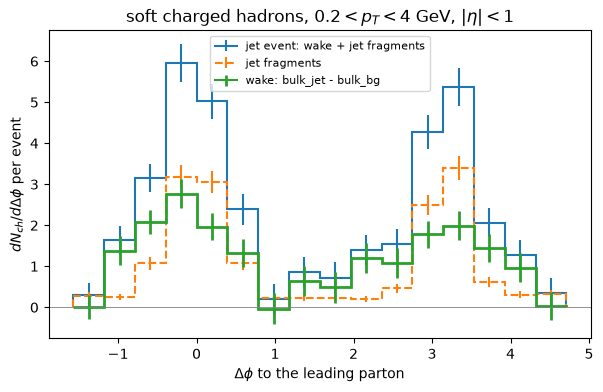

In [4]:
import hist
import mplhep as mh
import matplotlib.pyplot as plt

def lead_phi(info):
    """Azimuth of the event's hardest shower initiator."""
    ini = info.initiators()                         # shower, pid, pstat, px, py, pz, E, ...
    k = np.argmax(np.hypot(ini[:, 3], ini[:, 4]))
    return np.arctan2(ini[k, 4], ini[k, 3])

def dphi(ev, info):                                 # in [-pi/2, 3pi/2)
    return np.mod(ev.phi - lead_phi(info) + np.pi / 2, 2 * np.pi) - np.pi / 2

soft = lambda ev, info: ev.charged & (ev.pt > 0.2) & (ev.pt < 4) & (np.abs(ev.eta) < 1)

def to_hist(values, errors, edges, name, label):
    h = hist.Hist(hist.axis.Variable(edges, name=name, label=label), storage=hist.storage.Weight())
    h.view().value, h.view().variance = values, np.asarray(errors) ** 2
    return h

edges = np.linspace(-np.pi / 2, 3 * np.pi / 2, 17)
wake = to_hist(*r.jet_minus_background(dphi, edges, mask=soft), edges, "dphi", r"$\Delta\phi$")
full = to_hist(*r.jet_minus_background(dphi, edges, mask=soft, fragments=True), edges, "dphi", r"$\Delta\phi$")
frag = to_hist(*r.hist("jet_frag", dphi, edges, mask=soft), edges, "dphi", r"$\Delta\phi$")

fig, ax = plt.subplots(figsize=(7, 4))
width = edges[1] - edges[0]
mh.histplot(full / width, ax=ax, label="jet event: wake + jet fragments", flow="none")
mh.histplot(frag / width, ax=ax, label="jet fragments", flow="none", ls="--")
mh.histplot(wake / width, ax=ax, label="wake: bulk_jet - bulk_bg", flow="none", lw=2)
ax.axhline(0, color="0.5", lw=0.6)
ax.set(ylabel=r"$dN_{ch}/d\Delta\phi$ per event", xlabel=r"$\Delta\phi$ to the leading parton",
       title=r"soft charged hadrons, $0.2<p_T<4$ GeV, $|\eta|<1$")
ax.legend(fontsize=8);

**What to notice.**

- **The wake sits around both jets.** It has a peak near $\Delta\phi = 0$ and another near
  $\pi$, each broader than the jet's own fragments. The fluid carries the deposited energy
  along the jet's direction and spreads it in angle (the Mach-cone front of tutorial 06).
- **The wake is a sizable part of the soft hadrons of the jet event.** Below 4 GeV it adds to
  the fragments over a wide range of angles. A measured jet with a large radius therefore
  contains medium response, and a jet with a small radius loses part of it.
- **No significant depletion is visible here.** The diffusion wake of tutorial 06 is a deficit
  of energy density behind the jet. In hadrons it is spread over a large region and is small
  compared with the excess. Finding it takes many more events (and is an active topic of
  measurements).

## 4. The wake's energy in hadrons

Per event, the energy of all wake hadrons (all $\eta$, all species), next to the energy the
jet deposited in the fluid:

In [5]:
import pandas as pd
E_wake = np.array([r.jet_minus_background(None, None, weights="E", events=[g]) for g in range(r.n_events)])[:, :, 0]
with te.h5(SET, "AuAu_0_10_jet_seed0101.h5") as f:          # the pair file: its diagnostics only
    E_dep = f["diag/E_droplets"][:]
pd.DataFrame({"deposited [GeV]": E_dep, "wake hadrons E [GeV]": E_wake[:, 0],
              "error": E_wake[:, 1]}).round(1)

,deposited [GeV],wake hadrons E [GeV],error
0,54.1,31.4,2.6
1,34.4,30.2,2.6
2,27.9,25.6,2.2
3,15.8,17.3,1.7
4,19.4,18.3,2.0


**What to notice.** The wake, and the energy the jet put into the fluid, are visible at hadron
level too: each event's wake carries tens of GeV in hadrons, and the more energy a jet
deposited, the larger its wake. The hadrons are sampled from the freeze-out surface that MUSIC
found during the run, on its own grid.

## 5. The wake's spectrum and chemistry

Is the wake just "more of the same bulk", or different? Its $p_T$ spectrum, normalised to one
hadron, against the background's:

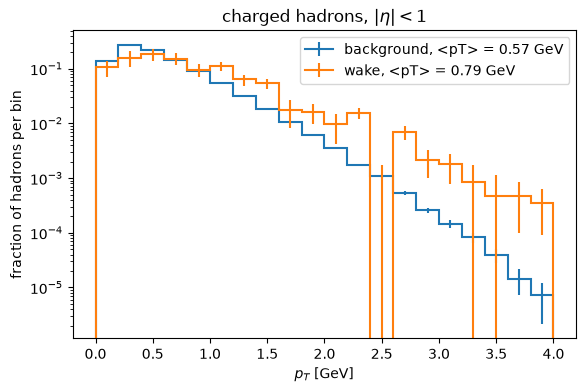

In [6]:
pt_edges = np.linspace(0, 4, 21)
w_pt = to_hist(*r.jet_minus_background("pt", pt_edges, mask=mid_charged), pt_edges, "pt", r"$p_T$ [GeV]")
b_pt = to_hist(*r.hist("bulk_bg", "pt", pt_edges, mask=mid_charged), pt_edges, "pt", r"$p_T$ [GeV]")

c = w_pt.axes[0].centers
mean_pt = lambda h: (h.values() * c).sum() / h.values().sum()
fig, ax = plt.subplots(figsize=(6.5, 4))
mh.histplot(b_pt / b_pt.sum().value, ax=ax, label=f"background, <pT> = {mean_pt(b_pt):.2f} GeV", flow="none")
mh.histplot(w_pt / w_pt.sum().value, ax=ax, label=f"wake, <pT> = {mean_pt(w_pt):.2f} GeV", flow="none")
ax.set(ylabel="fraction of hadrons per bin", yscale="log", title=r"charged hadrons, $|\eta|<1$")
ax.legend();

In [7]:
rows = []
for sp, label in [("pi", "pi+-"), ("K", "K+-"), ("p+pbar", "p, pbar")]:
    w, we = r.jet_minus_background(None, None, mask=sp)
    b, be = r.total("bulk_bg", mask=sp)
    rows.append((label, num(w), num(we), num(b)))
chem = pd.DataFrame(rows, columns=["species", "wake", "error", "background"]).set_index("species")
for col in ["wake", "background"]:
    chem[col + " / pi"] = chem[col] / chem.loc["pi+-", col]
chem.round(3)

,wake,error,background,wake / pi,background / pi
species,,,,,
pi+-,9.457,0.634,3827.995,1.000,1.000
K+-,1.649,0.250,698.260,0.174,0.182
"p, pbar",0.772,0.159,300.500,0.082,0.079


**What to notice.**

- **The wake is harder than the bulk:** its mean $p_T$ is about 0.8 GeV against 0.57 GeV.
  Its hadrons come from fluid the jet heated and pushed, which moves faster toward the
  surface than the surrounding medium. The flow blue-shifts their spectrum.
- **Its chemistry is the bulk's.** The K/π and p/π ratios of the wake agree with the
  background's within errors: the wake freezes out at the same temperature, so it produces
  hadron species in the same thermal proportions. Only the flow (the $p_T$) differs.

These are 5 events from one background. The campaign analysis
(`analysis/wake_hadrons.py`, on 285 events) found the same: a wake with thermal chemistry, a
harder spectrum, and energy balance within errors.

### Check your result

In [8]:
import json
exp = json.load(open("expected/07_hadron_pair.json"))
np.testing.assert_allclose(num(d_paired), exp["dN_mid_charged"], rtol=1e-6)
np.testing.assert_allclose(E_wake[:, 0], exp["E_wake"], rtol=1e-6)
np.testing.assert_allclose(mean_pt(w_pt), exp["mean_pt_wake"], rtol=1e-6)
assert r.correlated and num(e_paired) < num(e_indep) / 2
print("All checks pass.")

All checks pass.


## Exercises

1. **The wake per event.** Pass `events=[g]` to `jet_minus_background` and redraw the
   $\Delta\phi$ wake for event 0 and event 1 separately. Which of the two jets made the larger
   wake? Compare with the droplet energies of tutorial 06.
2. **The wake in $\Delta\eta$.** Replace $\Delta\phi$ by $\Delta\eta$ to the leading parton (its
   pseudorapidity is `np.arcsinh(pz / pT)` of the initiator). How far in $\eta$ does the wake
   reach?
3. **Inside a jet cone.** Count the wake's charged hadrons within $\Delta R < 0.4$ of the
   leading parton, and within $\Delta R < 1.5$. What fraction of the wake would a jet of radius
   0.4 contain?
4. **Independent sampling.** How many events would you need for the same error on the
   midrapidity difference without correlated sampling? (Use `e_indep` and `e_paired`.)

## Next steps

- Jets with FastJet, and the wake's effect on them: tutorial 08 and [Jets with FastJet](https://jhputschke.github.io/js-contrib/analysis/jets/).
- The campaign version of this analysis: `analysis/wake_hadrons.py` ([Hydro and hadrons together](https://jhputschke.github.io/js-contrib/analysis/hydro-hadrons/#jet-minus-background-in-hadrons)).
- Correlated sampling, in detail: [Hadrons](https://jhputschke.github.io/js-contrib/analysis/hadrons/#2-histograms-totals-and-the-wake).